## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, spearmanr, probplot

In [4]:
path = "C:/Users/Raquel Marques/Desktop/Ironhack/Labs/lab-eda-univariate-main/amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(path, sep=",")

df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [5]:
best_seller_table = pd.crosstab(df["category"],df["isBestSeller"])

display(best_seller_table)


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [10]:
best_seller_proportion = pd.crosstab(df['category'],df['isBestSeller'],normalize='index')

best_seller_proportion = best_seller_proportion[True].sort_values(ascending=False)

best_seller_proportion

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Name: True, Length: 296, dtype: float64

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [11]:
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295


In [12]:
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

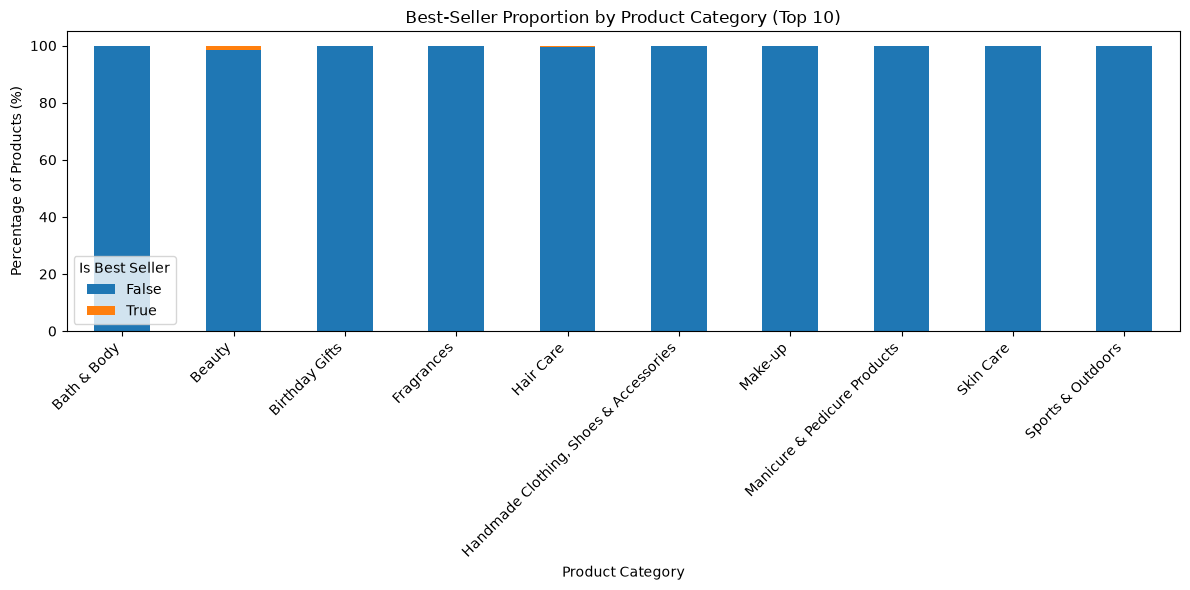

In [14]:
top_categories = df['category'].value_counts().head(10).index

top_table = pd.crosstab(
    df[df['category'].isin(top_categories)]['category'],
    df[df['category'].isin(top_categories)]['isBestSeller'],
    normalize='index'
) * 100

top_table.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.title('Best-Seller Proportion by Product Category (Top 10)')
plt.xlabel('Product Category')
plt.ylabel('Percentage of Products (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Is Best Seller')
plt.tight_layout()
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [15]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
].copy()

print("Original dataset shape:", df.shape)
print("Dataset without outliers:", df_no_outliers.shape)
print("Number of outliers removed:", len(df) - len(df_no_outliers))

Original dataset shape: (2443651, 9)
Dataset without outliers: (2115963, 9)
Number of outliers removed: 327688


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

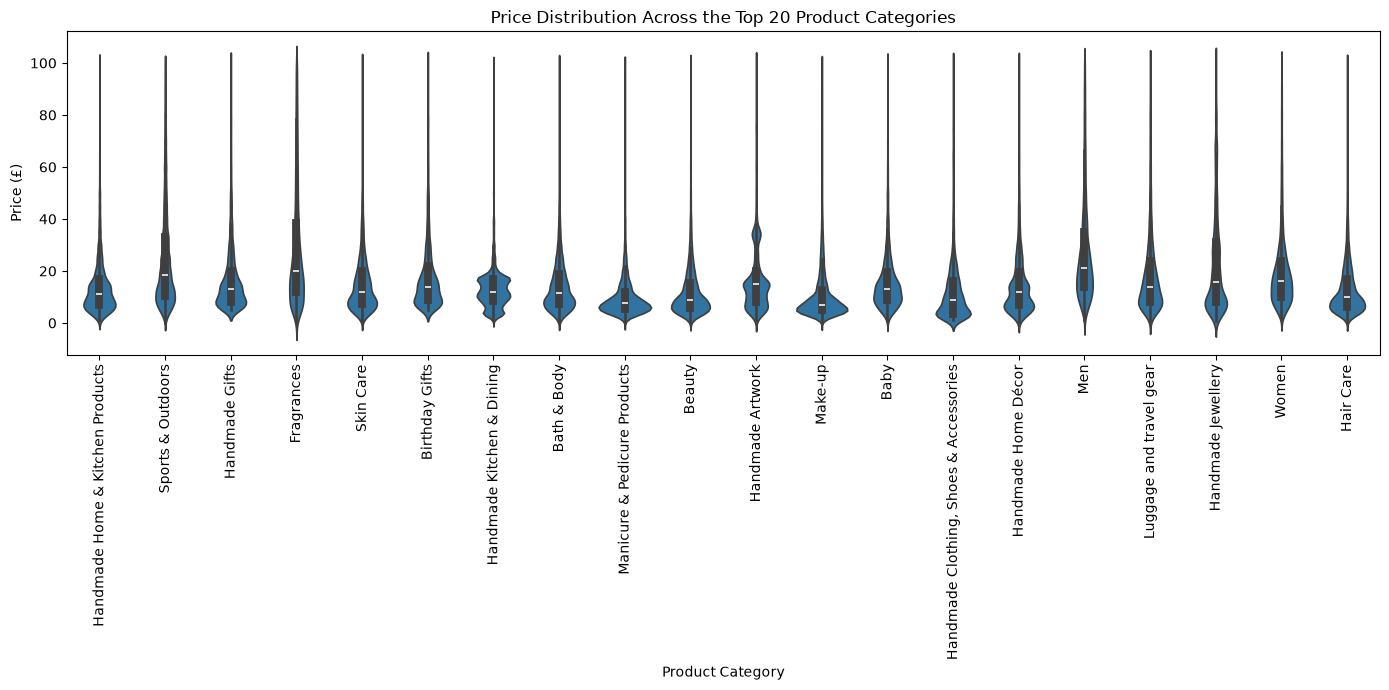

In [16]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index

df_top_20 = df_no_outliers[
    df_no_outliers['category'].isin(top_20_categories)
]

plt.figure(figsize=(14, 7))
sns.violinplot(data=df_top_20, x='category', y='price')

plt.title('Price Distribution Across the Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price (£)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [17]:
median_prices = (
    df_no_outliers.groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

<Axes: xlabel='category'>

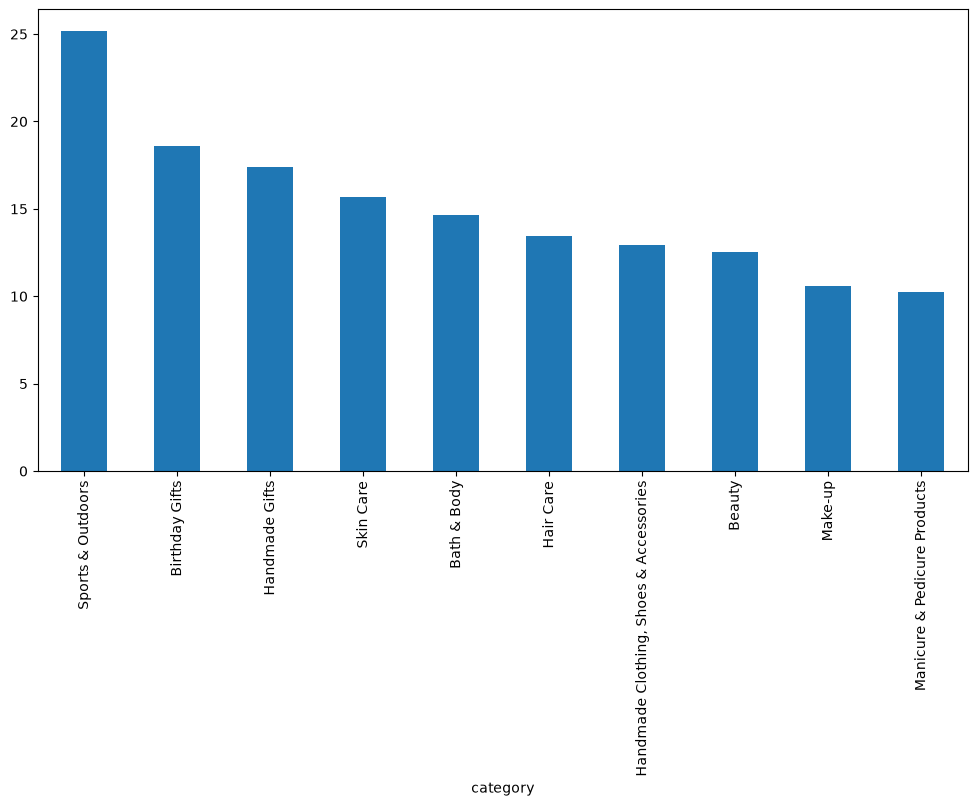

In [18]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

df_top_10 = df_no_outliers[
    df_no_outliers['category'].isin(top_10_categories)
]

average_prices = (
    df_top_10.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

average_prices.plot(kind='bar', figsize=(12, 6))

In [19]:
average_price_all = (
    df_no_outliers.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

print("Category with the highest average price:", average_price_all.idxmax())
print("Highest average price (£):", round(average_price_all.max(), 2))

Category with the highest average price: Motherboards
Highest average price (£): 68.77


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

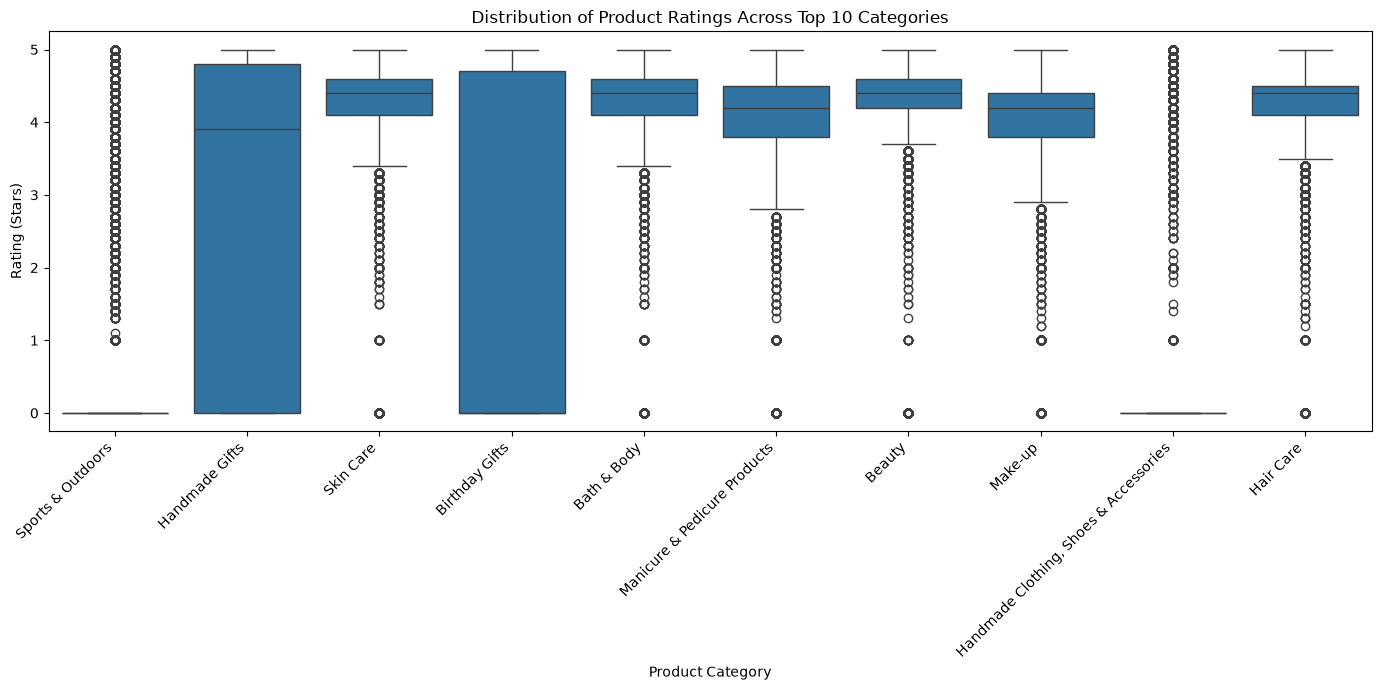

In [26]:
# Select the top 10 categories based on product count
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

# Filter the dataset
df_top_10 = df_no_outliers[
    df_no_outliers['category'].isin(top_10_categories)
]

# Create side-by-side box plots
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_top_10,
    x='category',
    y='stars'
)

plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Rating (Stars)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [28]:
median_ratings = (
    df_no_outliers.groupby('category')['stars']
    .median()
    .dropna()
    .sort_values(ascending=False)
)

print(median_ratings.head(10))

print("\nCategory with the highest median rating:", median_ratings.idxmax())
print("Highest median rating:", median_ratings.max())

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

Category with the highest median rating: Computer Memory
Highest median rating: 4.7


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [29]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])

print("Correlation coefficient:", correlation)

Correlation coefficient: -0.0776729987818137


In [30]:
price_stars = df_no_outliers[['price', 'stars']].dropna()

r, p_value = pearsonr(price_stars['price'], price_stars['stars'])

print("Pearson correlation coefficient:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")


Pearson correlation coefficient: -0.07767299878181347
P-value: 0.0
The correlation is statistically significant.


2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

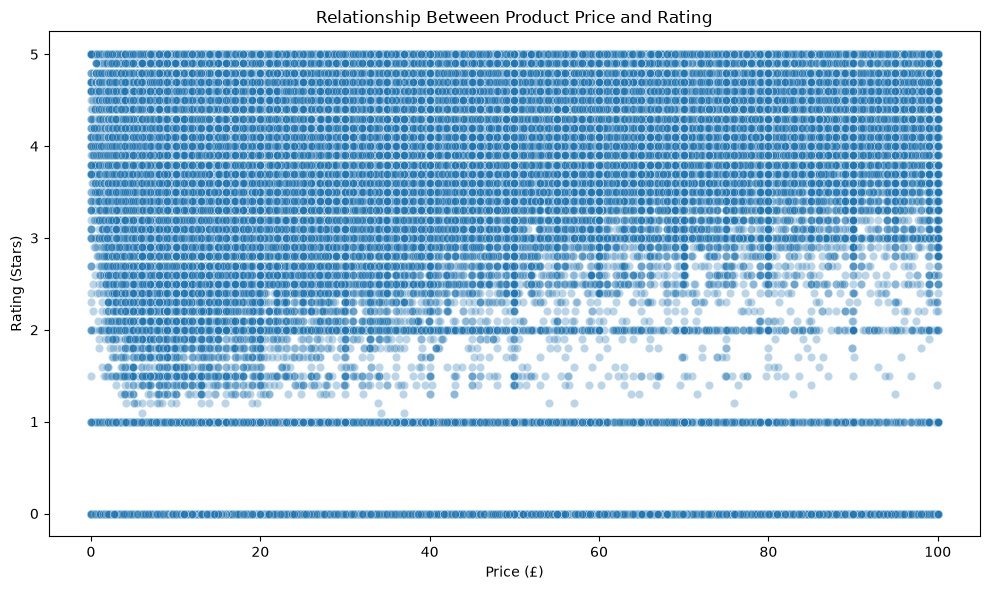

In [31]:
plot_data = df_no_outliers[['price', 'stars']].dropna()

# Create scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_data, x='price', y='stars', alpha=0.3)

plt.title('Relationship Between Product Price and Rating')
plt.xlabel('Price (£)')
plt.ylabel('Rating (Stars)')
plt.tight_layout()
plt.show()


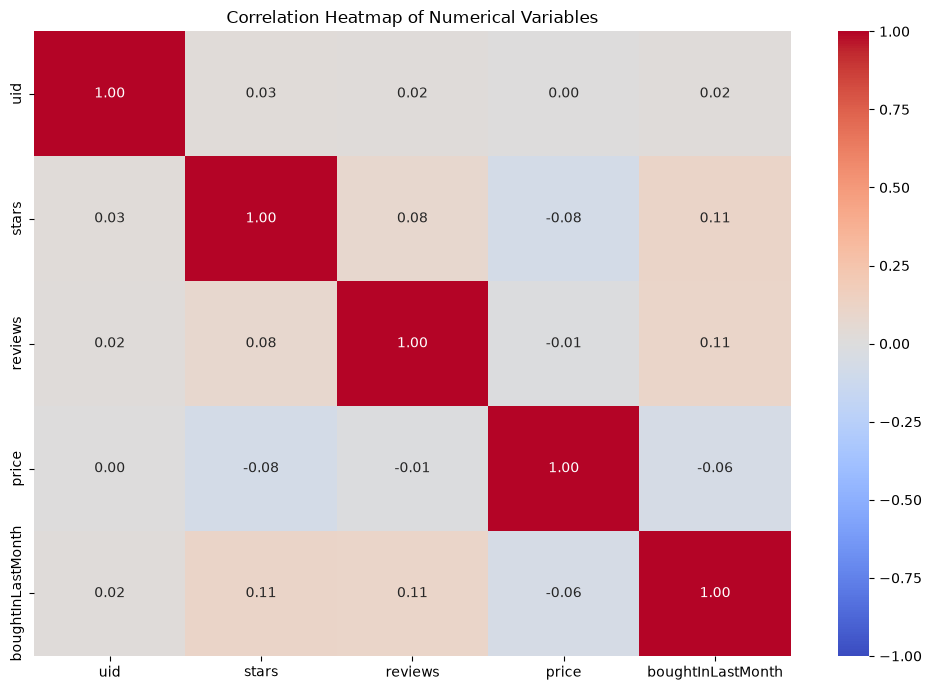

In [32]:
numeric_data = df_no_outliers.select_dtypes(include='number')

# Calculate correlations
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

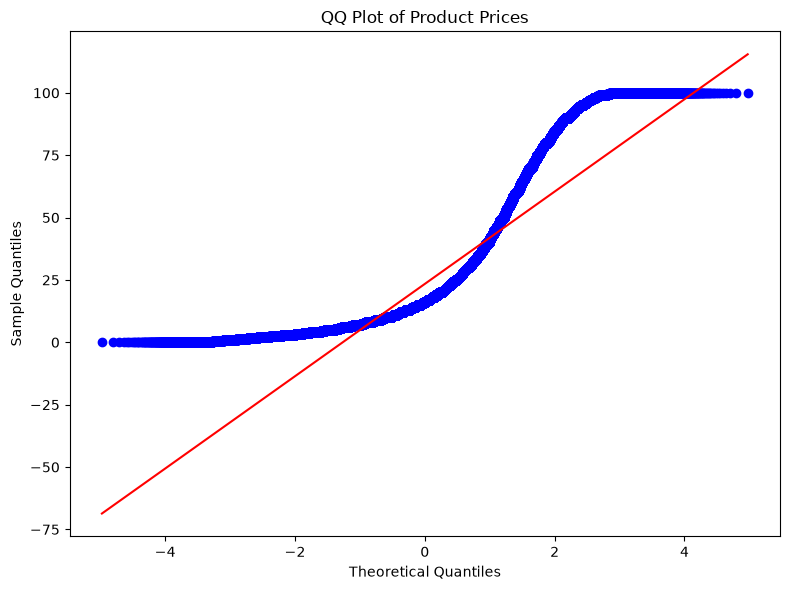

In [34]:

import scipy.stats as stats

# Remove missing values from price
prices = df_no_outliers['price'].dropna()

# Create QQ plot
plt.figure(figsize=(8, 6))
stats.probplot(prices, dist='norm', plot=plt)

plt.title('QQ Plot of Product Prices')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.tight_layout()
plt.show()

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

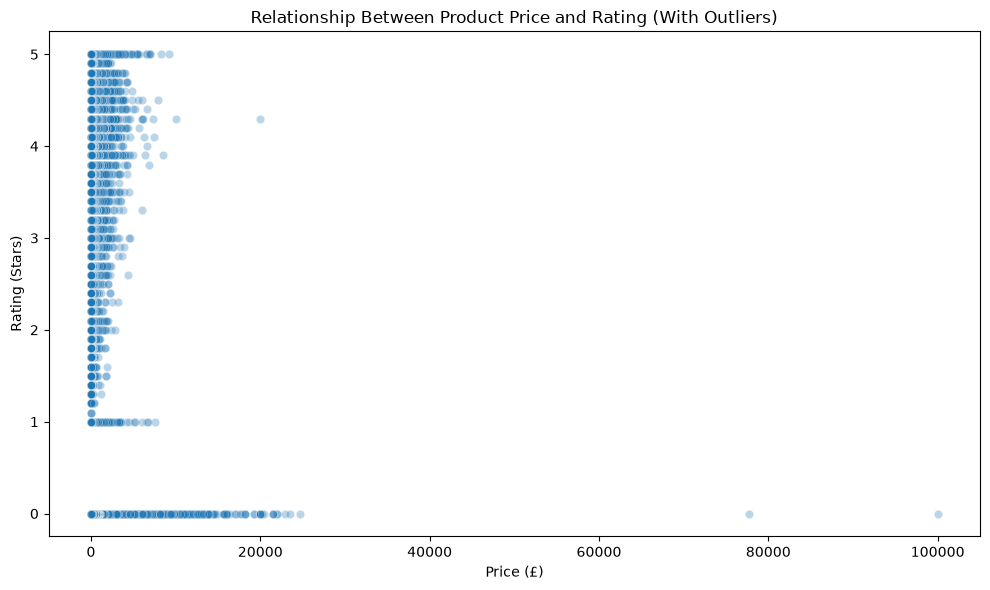

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='price', y='stars', alpha=0.3)

plt.title('Relationship Between Product Price and Rating (With Outliers)')
plt.xlabel('Price (£)')
plt.ylabel('Rating (Stars)')
plt.tight_layout()
plt.show()

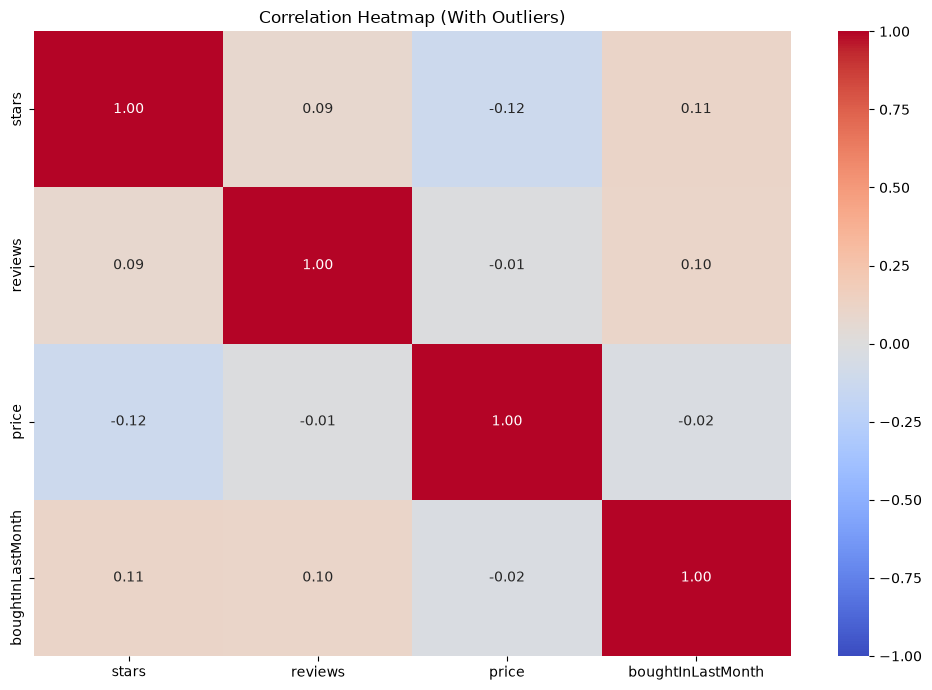

In [36]:
numeric_data = df.select_dtypes(include='number')

# Remove ID columns, as they are not meaningful for correlation
numeric_data = numeric_data.drop(columns=['uid'], errors='ignore')

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap (With Outliers)')
plt.tight_layout()
plt.show()

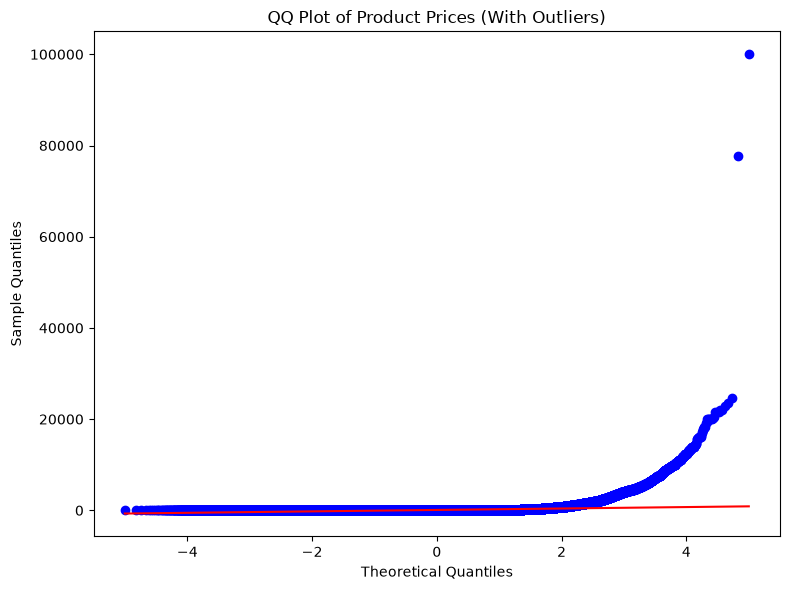

In [37]:
import scipy.stats as stats

prices = df['price'].dropna()

plt.figure(figsize=(8, 6))
stats.probplot(prices, dist='norm', plot=plt)

plt.title('QQ Plot of Product Prices (With Outliers)')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.tight_layout()
plt.show()

In [38]:
comparison = pd.DataFrame({
    'With Outliers': df['price'].describe(),
    'Without Outliers': df_no_outliers['price'].describe()
})

print(comparison)

       With Outliers  Without Outliers
count   2.443651e+06      2.115963e+06
mean    8.924381e+01      2.340827e+01
std     3.456089e+02      2.051335e+01
min     0.000000e+00      0.000000e+00
25%     9.990000e+00      9.130000e+00
50%     1.909000e+01      1.599000e+01
75%     4.599000e+01      2.999000e+01
max     1.000000e+05      9.999000e+01
